Tugas Machine Learning 12

12.1 Persiapan Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

12.2 Import Dataset

In [ ]:
digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

12.3 Preprocessing

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

12.4 Training Model (Keras Sequential API)

In [ ]:
model = keras.Sequential([
    keras.layers.Dense(64, activation="relu", input_shape=(X_train.shape[1],)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax")]) # 10 kelas angka (0-9)

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train, validation_split=0.2, epochs=50, batch_size=32, verbose=0)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12.5 Evaluasi

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Test : {test_acc:.3f}")

Akurasi Test : 0.981


12.6 Visualisai

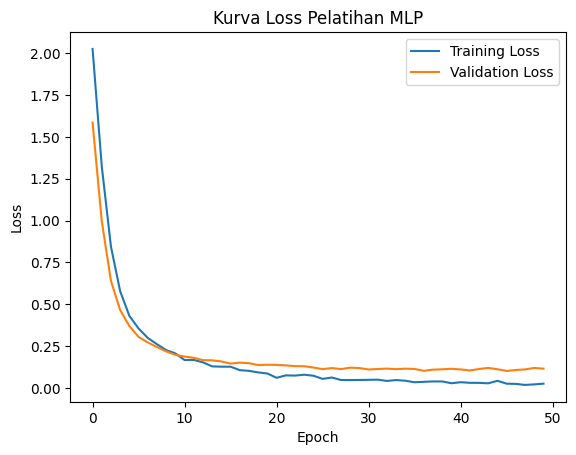

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label = "Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Kurva Loss Pelatihan MLP")
plt.legend()
plt.show()

12.7 Praktikum

=== PRAKTIKUM 1 (12.7): Eksperimen Arsitektur MLP ===
Arsitektur [32]: val_accuracy akhir = 0.938
Arsitektur [64, 32]: val_accuracy akhir = 0.958
Arsitektur [128, 64, 32]: val_accuracy akhir = 0.948

Arsitektur        Parameter  Val acc  Test acc
[32]                  2,410    0.938     0.958
[64, 32]              6,570    0.958     0.958
[128, 64, 32]        18,986    0.948     0.967

Arsitektur dengan val_accuracy tertinggi: [64, 32]


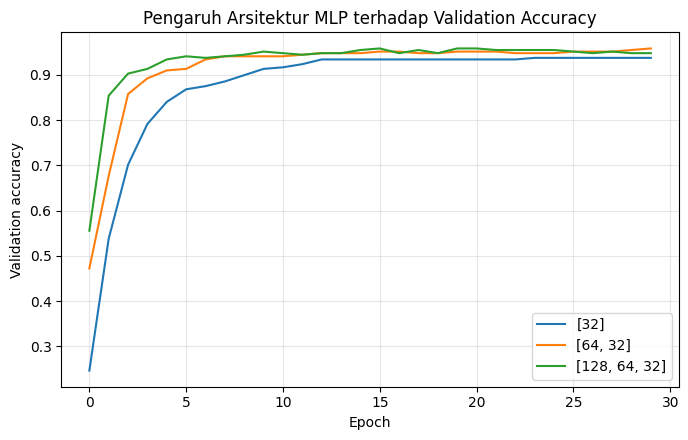

In [ ]:
import ast
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

try:
    from tensorflow import keras      # TensorFlow 2.x
except ImportError:
    import keras                      # Keras 3 standalone

keras.utils.set_random_seed(42)       # hasil lebih mudah diulang

# --- Persiapan data ---
# Dataset: digits (8x8 piksel, 10 kelas) agar sesuai dengan Dense(10).
# Jika di praktikum sebelumnya kamu memakai MNIST, ganti blok ini dengan:
#   (X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
#   X_train = X_train.reshape(-1, 784) / 255.0
#   X_test = X_test.reshape(-1, 784) / 255.0
X, y = load_digits(return_X_y=True)
X = X / 16.0                           # skala piksel 0-16 -> 0-1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# =====================================================================
# PRAKTIKUM 1 (Praktikum 12.7) - Eksperimen Arsitektur MLP
# Tujuan: mengamati pengaruh jumlah hidden layer dan neuron
#         terhadap performa model.
# =====================================================================
print("=== PRAKTIKUM 1 (12.7): Eksperimen Arsitektur MLP ===")
arsitektur_list = [[32], [64, 32], [128, 64, 32]]
hasil_127 = {}
for arsitektur in arsitektur_list:
    layers = [keras.layers.Dense(n,
        activation="relu") for n in arsitektur]
    model = keras.Sequential(
        [keras.layers.Input(shape=(X_train.shape[1],))] + layers
        + [keras.layers.Dense(10, activation="softmax")])
    model.compile(optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    history = model.fit(X_train, y_train,
        validation_split=0.2, epochs=30, verbose=0)
    print(f"Arsitektur {arsitektur}: val_accuracy akhir = "
        f"{history.history['val_accuracy'][-1]:.3f}")

    # --- tambahan untuk analisis ---
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    hasil_127[str(arsitektur)] = {
        "history": history.history,
        "val_acc": history.history["val_accuracy"][-1],
        "test_acc": test_acc,
        "params": model.count_params(),
    }

print(f"\n{'Arsitektur':<16}{'Parameter':>11}{'Val acc':>9}{'Test acc':>10}")
for nama, h in hasil_127.items():
    print(f"{nama:<16}{h['params']:>11,}{h['val_acc']:>9.3f}"
          f"{h['test_acc']:>10.3f}")

terbaik = max(hasil_127, key=lambda k: hasil_127[k]["val_acc"])
print(f"\nArsitektur dengan val_accuracy tertinggi: {terbaik}")

plt.figure(figsize=(7, 4.5))
for nama, h in hasil_127.items():
    plt.plot(h["history"]["val_accuracy"], label=f"{nama}")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Pengaruh Arsitektur MLP terhadap Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("mlp_arsitektur.png", dpi=110)
plt.show()


12.8 Praktikum


=== PRAKTIKUM 2 (12.8): Early Stopping ===
Pelatihan berhenti pada epoch: 29
Epoch dengan val_loss terendah: 24
Tanpa early stopping : 100 epoch, test acc = 0.969, val_loss akhir = 0.1647
Dengan early stopping: 29 epoch, test acc = 0.956, val_loss terbaik = 0.1621


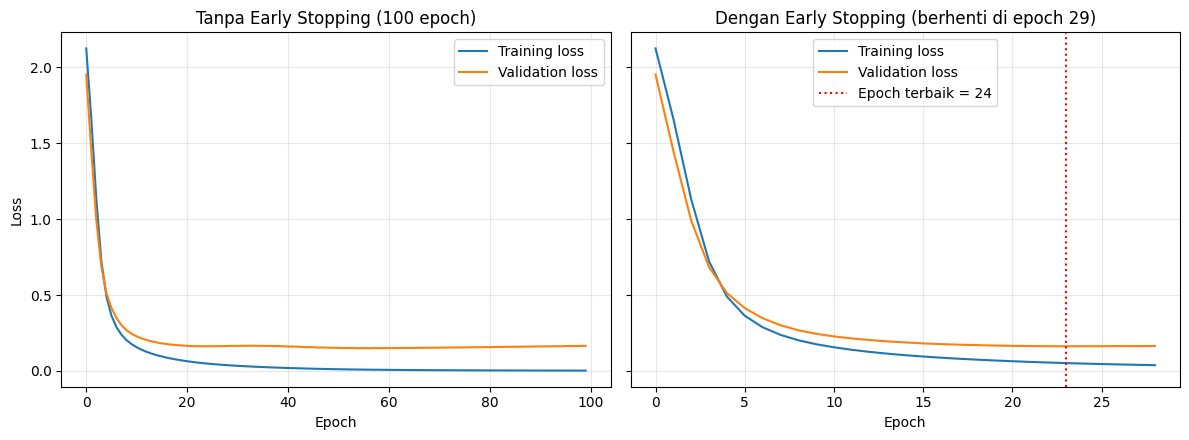

In [ ]:
print("\n=== PRAKTIKUM 2 (12.8): Early Stopping ===")


def bangun_model(arsitektur):
    """Model BARU (bobot acak) agar tidak melanjutkan model dari 12.7."""
    layers = [keras.layers.Dense(n, activation="relu") for n in arsitektur]
    m = keras.Sequential(
        [keras.layers.Input(shape=(X_train.shape[1],))] + layers
        + [keras.layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
    return m


arsitektur_pilihan = ast.literal_eval(terbaik)  # terbaik dari 12.7

# (a) Tanpa early stopping: 100 epoch penuh
keras.utils.set_random_seed(42)
model = bangun_model(arsitektur_pilihan)
hist_tanpa = model.fit(X_train, y_train, validation_split=0.2,
                       epochs=100, verbose=0)
acc_tanpa = model.evaluate(X_test, y_test, verbose=0)[1]

# (b) Dengan early stopping (sesuai buku)
keras.utils.set_random_seed(42)
model = bangun_model(arsitektur_pilihan)
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss",
    patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train, validation_split=0.2,
    epochs=100, callbacks=[early_stop], verbose=0)
print("Pelatihan berhenti pada epoch:",
    len(history.history["loss"]))

# --- tambahan untuk analisis ---
acc_es = model.evaluate(X_test, y_test, verbose=0)[1]
epoch_terbaik = int(np.argmin(history.history["val_loss"])) + 1
print(f"Epoch dengan val_loss terendah: {epoch_terbaik}")
print(f"Tanpa early stopping : 100 epoch, test acc = {acc_tanpa:.3f}, "
      f"val_loss akhir = {hist_tanpa.history['val_loss'][-1]:.4f}")
print(f"Dengan early stopping: {len(history.history['loss'])} epoch, "
      f"test acc = {acc_es:.3f}, "
      f"val_loss terbaik = {min(history.history['val_loss']):.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
ax1.plot(hist_tanpa.history["loss"], label="Training loss")
ax1.plot(hist_tanpa.history["val_loss"], label="Validation loss")
ax1.set_title("Tanpa Early Stopping (100 epoch)")
ax2.plot(history.history["loss"], label="Training loss")
ax2.plot(history.history["val_loss"], label="Validation loss")
ax2.axvline(epoch_terbaik - 1, color="red", linestyle=":",
            label=f"Epoch terbaik = {epoch_terbaik}")
ax2.set_title(f"Dengan Early Stopping (berhenti di epoch "
              f"{len(history.history['loss'])})")
for ax in (ax1, ax2):
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
ax1.set_ylabel("Loss")
plt.tight_layout()
plt.savefig("early_stopping.png", dpi=110)
plt.show()